In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import seaborn as sns

from sklearn.impute import SimpleImputer


In [ ]:
df= pd.read_csv("bank.csv")
df.head(15)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes
5,56,management,married,tertiary,no,830.0,yes,yes,unknown,6.0,may,1201.0,1.0,-1.0,0.0,unknown,yes
6,60,retired,divorced,secondary,no,545.0,yes,no,unknown,6.0,may,1030.0,1.0,-1.0,0.0,unknown,yes
7,37,technician,married,secondary,no,1.0,yes,no,unknown,6.0,may,608.0,1.0,-1.0,0.0,unknown,yes
8,28,services,single,secondary,no,5090.0,yes,no,unknown,6.0,may,1297.0,3.0,-1.0,0.0,unknown,yes
9,38,admin.,single,secondary,no,100.0,yes,no,unknown,7.0,may,786.0,1.0,-1.0,0.0,unknown,yes


## ***EDA***

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [ ]:
df.isna().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


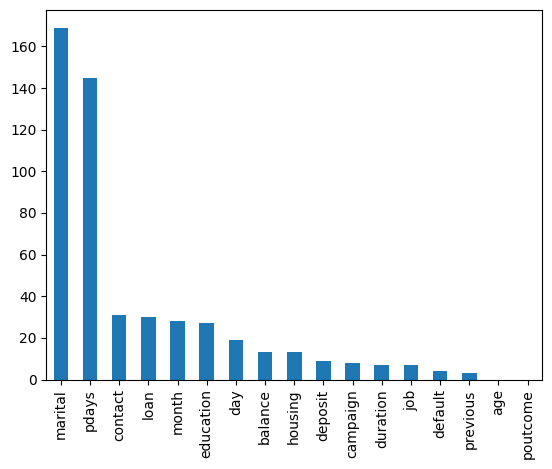

In [ ]:
df.isna().sum().sort_values(ascending=False ).plot(kind = "bar")
plt.show()

In [ ]:
obj_col = ['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month']
obj_col

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month']

In [ ]:
numeric_col = [ 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
numeric_col

['balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

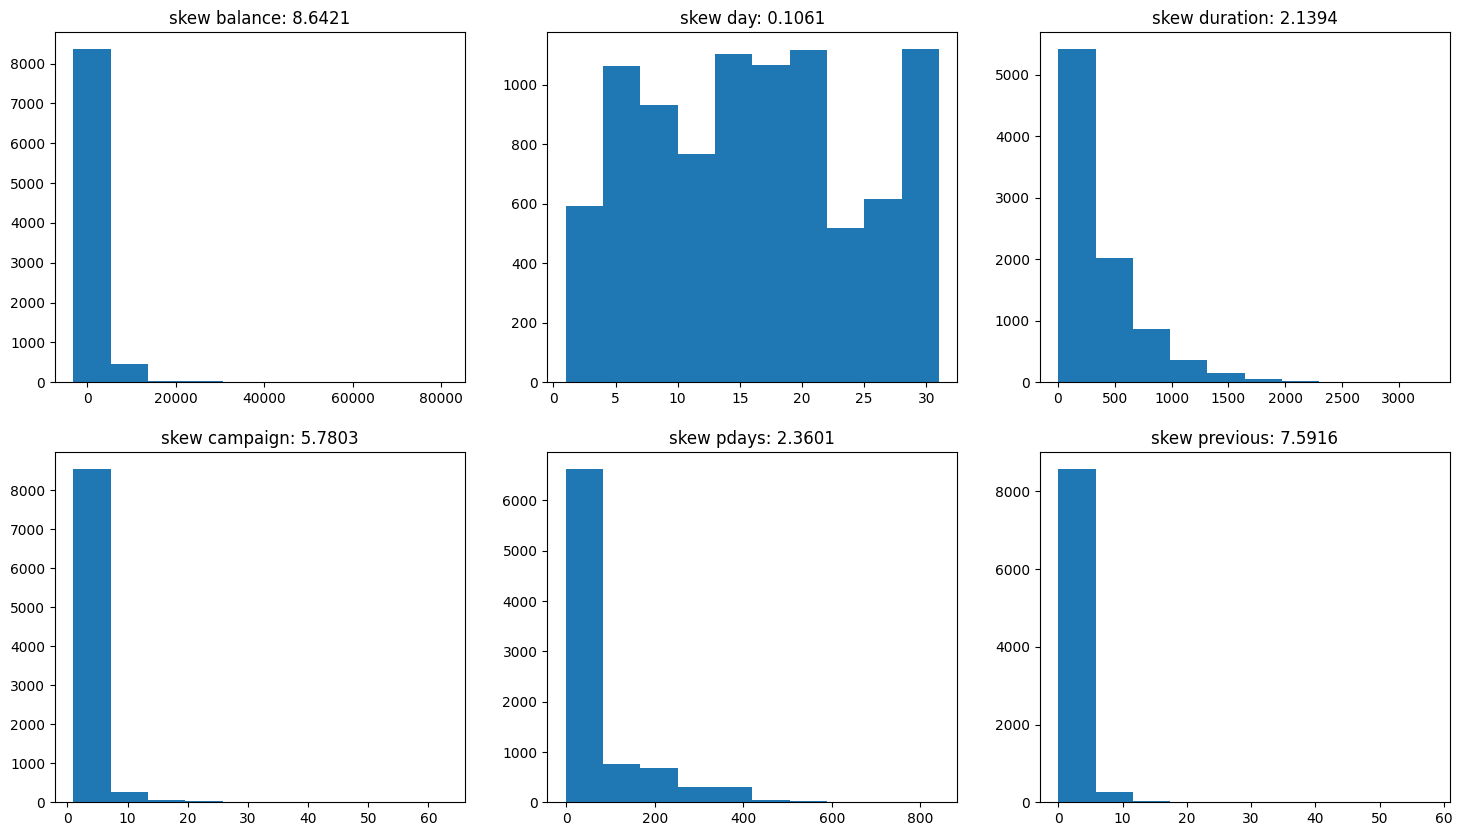

In [ ]:
plt.figure(figsize=(18, 10))
for j , col in enumerate(numeric_col):
  plt.subplot(2 , 3 , j+1)
  plt.hist(df[col])
  plt.title(f"skew {col}: {df[col].skew():.4f}")


In [ ]:
df = df.dropna(subset=['deposit'])

In [ ]:
X = df.drop("deposit", axis=1)
y = df["deposit"]
y = y.map({'yes' : 1, 'no' : 0})

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
most_frequent_imputer = SimpleImputer(missing_values=np.nan, strategy="most_frequent")
for col in obj_col:
    X_train[obj_col] = most_frequent_imputer.fit_transform(X_train[obj_col])
    X_test[obj_col] = most_frequent_imputer.transform(X_test[obj_col])
print(X_train[obj_col].isna().sum())

job          0
marital      0
education    0
default      0
housing      0
loan         0
contact      0
month        0
dtype: int64


In [ ]:
numeric_col

['balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

In [ ]:
mean_imputer = SimpleImputer(missing_values=np.nan, strategy="mean")
median_imputer = SimpleImputer(missing_values=np.nan, strategy="median")

for col in numeric_col:
  if X_train[col].skew() > 0.5:
    X_train[[col]] = median_imputer.fit_transform(X_train[[col]])
    X_test[[col]] = median_imputer.transform(X_test[[col]])
  else:
    X_train[[col]] = mean_imputer.fit_transform(X_train[[col]])
    X_test[[col]] = mean_imputer.transform(X_test[[col]])

print(X_train[numeric_col].isna().sum())

balance     0
day         0
duration    0
campaign    0
pdays       0
previous    0
dtype: int64


In [ ]:
X_train.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
for col in X_train.select_dtypes("object").columns:
  print(f"Number of Unique value {col}: {X_train[col].nunique()}")
  print(f"Unique value {col}: {X_train[col].unique()}")
  print("*" *50)


Number of Unique value job: 12
Unique value job: ['management' 'technician' 'admin.' 'student' 'retired' 'unknown'
 'services' 'self-employed' 'blue-collar' 'housemaid' 'unemployed'
 'entrepreneur']
**************************************************
Number of Unique value marital: 3
Unique value marital: ['married' 'divorced' 'single']
**************************************************
Number of Unique value education: 4
Unique value education: ['tertiary' 'secondary' 'unknown' 'primary']
**************************************************
Number of Unique value default: 2
Unique value default: ['no' 'yes']
**************************************************
Number of Unique value housing: 2
Unique value housing: ['yes' 'no']
**************************************************
Number of Unique value loan: 2
Unique value loan: ['no' 'yes']
**************************************************
Number of Unique value contact: 3
Unique value contact: ['cellular' 'unknown' 'telephone']
**********

In [ ]:
encoding = [col for col in X_train.select_dtypes("object").columns]

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in encoding:
  X_train[col] = le.fit_transform(X_train[col])
  X_test[col] = le.transform(X_test[col])

In [ ]:
X_train.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
7208,53,4,1,2,0,0.0,1,0,0,14.0,5,85.0,3.0,-1.0,0.0,3
7486,34,9,1,1,0,2019.0,1,1,2,27.0,6,102.0,1.0,-1.0,0.0,3
2089,48,4,0,2,0,17964.0,1,0,0,1.0,11,120.0,1.0,98.0,5.0,2
1574,49,4,1,2,0,85.0,1,0,0,14.0,8,590.0,5.0,359.0,1.0,1
8428,35,0,2,1,0,855.0,1,0,2,12.0,8,241.0,3.0,-1.0,0.0,3


In [ ]:
X_train.describe()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
count,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000,6232.000000
mean,41.244865,4.495026,1.202022,1.278883,0.016046,1565.244544,0.476252,0.127407,0.484917,15.727653,5.451540,376.929557,2.511714,51.168164,0.827985,2.484756
std,11.848265,3.220457,0.619930,0.750894,0.125663,3386.371462,0.499476,0.333455,0.816554,8.395808,3.197991,349.720562,2.790472,107.157339,2.249399,0.992392
min,18.000000,0.000000,0.000000,0.000000,0.000000,-3058.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,1.000000,-1.000000,0.000000,0.000000
25%,32.000000,1.000000,1.000000,1.000000,0.000000,129.000000,0.000000,0.000000,0.000000,8.000000,3.000000,141.000000,1.000000,-1.000000,0.000000,2.000000
50%,39.000000,4.000000,1.000000,1.000000,0.000000,565.000000,0.000000,0.000000,0.000000,16.000000,6.000000,260.000000,2.000000,-1.000000,0.000000,3.000000
75%,49.000000,7.000000,2.000000,2.000000,0.000000,1757.000000,1.000000,0.000000,1.000000,22.000000,8.000000,504.000000,3.000000,40.250000,1.000000,3.000000
max,92.000000,11.000000,2.000000,3.000000,1.000000,81204.000000,1.000000,1.000000,2.000000,31.000000,11.000000,3284.000000,63.000000,842.000000,58.000000,3.000000


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.svm import SVC

In [ ]:
model = SVC(kernel = 'linear' , gamma = 'auto' , C = 0.1)
model.fit(X_train_scaled, y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [ ]:
print(model.score(X_train_scaled, y_train))

0.7966944801026957


In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
print(model.score(X_test_scaled, y_test))

0.7970797454137027


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
print(f'accuracy_score:{accuracy_score(y_test, y_pred)}')
print("*" *30)

print(f'classification_report  :{classification_report(y_test, y_pred)}')


accuracy_score:0.7970797454137027
******************************
classification_report  :              precision    recall  f1-score   support

           0       0.79      0.83      0.81      1399
           1       0.80      0.76      0.78      1272

    accuracy                           0.80      2671
   macro avg       0.80      0.80      0.80      2671
weighted avg       0.80      0.80      0.80      2671



confusion_matrix  :[[1156  243]
 [ 299  973]]


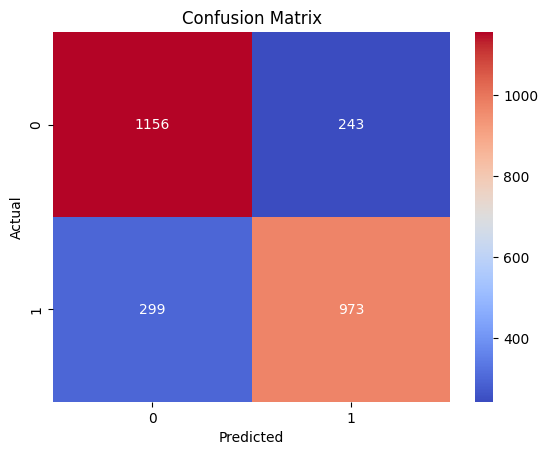

In [ ]:
print(f'confusion_matrix  :{confusion_matrix(y_test, y_pred)}')
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True , fmt= "d" , cmap='coolwarm')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
grid_parms = {
    "C" : [0.1, 1, 10, 100],
    'kernel' : ['linear', 'rpf' , 'poly', 'sigmoid'],
    'gamma'  : ['scale', 'auto']
}

In [36]:
grid = GridSearchCV(estimator=SVC(), param_grid=grid_parms, cv=5, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
40 fits failed out of a total of 160.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_pa

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto'],
                         'kernel': ['linear', 'rpf', 'poly', 'sigmoid']},
             scoring='accuracy')

In [46]:
print(grid.best_params_)
print(grid.best_score_)

{'C': 1, 'gamma': 'scale', 'kernel': 'poly'}
0.8052013113977559


In [47]:
best_model= grid.best_estimator_

In [48]:
y_pred_grid = grid.predict(X_test_scaled)

In [52]:
print(accuracy_score(y_test, y_pred_grid))
print(classification_report(y_test, y_pred_grid))

0.8049419692998877
              precision    recall  f1-score   support

           0       0.81      0.82      0.82      1399
           1       0.80      0.79      0.79      1272

    accuracy                           0.80      2671
   macro avg       0.80      0.80      0.80      2671
weighted avg       0.80      0.80      0.80      2671

